In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/pavanjitsubash/power-plant-data-steam-turbine-and-boiler-metrics/industrial_dataset.csv


In [2]:
df = pd.read_csv(
    "/kaggle/input/datasets/pavanjitsubash/power-plant-data-steam-turbine-and-boiler-metrics/industrial_dataset.csv"
)

df

,Timestamp,Main steam flow (t/h),Main steam temperature (boiler side) (℃),Main steam pressure (boiler side) (Mpa),Reheat steam temperature (boiler side) (℃),Superheater desuperheating water flow (t/h),Reheater desuperheating water flow (t/h),Feedwater temperature (℃),Feedwater flow (t/h),Flue gas temperature (℃),...,APH Leakage (%),Corrected Flue Gas Out Temperature (°C),APH Effectiveness (%),Coal Flow (t/h),Energy Input From Boiler (Kcal/h),NTHR (Kcal/Kwh),NPHR (Kcal/Kwh),Gross Load (MW),Nett Load (MW),HHV (Kcal/Kg)
0,2022-01-01 0:00:00,831.910828,566.878717,14.446013,565.074076,89.133230,3.534005,230.563896,838.034849,126.556083,...,3.145248,129.543482,69.868837,168.518184,7.175504e+08,2566.008735,2744.296044,295.240527,279.649889,4258.000000
1,2022-01-01 0:10:00,832.522069,566.959967,14.474907,564.877278,85.857222,4.352339,230.579426,838.411302,127.020317,...,3.270540,130.138310,69.786889,167.194722,7.119145e+08,2543.645818,2720.556496,295.522844,279.885623,4257.996387
2,2022-01-01 0:20:00,831.882230,566.977780,14.561818,564.923357,80.248958,4.215078,230.526694,838.058008,126.655042,...,3.564435,130.058288,69.877082,165.787834,7.059043e+08,2527.455845,2703.216962,295.093870,279.289591,4257.876726
3,2022-01-01 0:30:00,832.975865,566.749708,14.636212,564.928633,77.198160,3.636971,230.547290,838.435509,125.404809,...,3.894965,129.075632,70.244200,165.943615,7.063279e+08,2531.194330,2705.984839,295.123758,279.033867,4256.418966
4,2022-01-01 0:40:00,835.074332,566.507266,14.625856,564.860907,80.485476,3.230252,230.620138,839.703231,123.778227,...,4.027866,127.479518,70.700485,166.886946,7.092670e+08,2539.170644,2711.965413,295.661029,279.307840,4249.888012
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50086,2022-12-14 19:40:00,825.136581,566.671504,14.094808,565.526431,80.198831,2.415578,239.566141,845.088044,121.535879,...,4.128055,124.953257,71.042129,168.255583,7.115114e+08,2495.049147,2690.454933,299.526557,280.224306,4260.271102
50087,2022-12-14 19:50:00,825.237419,566.503465,14.196908,564.883750,79.001261,2.285004,233.999354,844.888691,121.914277,...,4.502602,124.547615,70.960739,168.326266,7.124705e+08,2515.156875,2698.736297,298.460842,280.219514,4256.214116
50088,2022-12-14 20:00:00,826.391105,566.409350,14.314812,564.955590,76.322116,1.421339,230.067955,847.523933,121.736837,...,4.231088,124.726715,71.021981,167.727906,7.111799e+08,2541.517756,2721.218752,296.536538,279.572568,4257.649932
50089,2022-12-14 20:10:00,827.382573,566.476844,14.398393,565.767901,77.202584,0.751251,231.352564,850.441658,121.631520,...,3.009065,124.060808,71.345805,167.324965,7.090064e+08,2545.386111,2739.887289,295.837962,279.512520,4257.373887


In [3]:
import pandas as pd

pd.set_option("display.max_columns", None)
display(df)

,Timestamp,Main steam flow (t/h),Main steam temperature (boiler side) (℃),Main steam pressure (boiler side) (Mpa),Reheat steam temperature (boiler side) (℃),Superheater desuperheating water flow (t/h),Reheater desuperheating water flow (t/h),Feedwater temperature (℃),Feedwater flow (t/h),Flue gas temperature (℃),Boiler oxygen level (%),Main steam temperature (turbine side) (℃),Main steam pressure (turbine side) (MPa),Reheat steam temperature (turbine side) (℃),Reheat steam pressure (turbine side) (MPa),Control stage pressure (Mpa),High exhaust pressure (Mpa),Feedwater pressure (MPa),Condenser vacuum (kPa),Circulating water outlet temperature (℃),SO2 (mg/m3),Nox (mg/m3),CO (mg/m3),CO2 (ppm),O2 (%),Velocity (m/s),Temp. (°C),Pressure (Kpa),Flow rate (KNm3/h),Opacity (%),Dust (mg/m3),Boiler Eff (%),Entalphy inlet MS (kj/kg),Entropi Inlet MS (Kj/Kg (Deg C)),Cold Reheat Pressure (Mpa),Cold Reheat Temperature (°C),Entalphy Cold Reheat (kj/kg),Entalphy Isentropis Cold Reheat (kj/kg),ΔP aktual (Kj/Kg),ΔHP isentropis (Kj/Kg),HP Turbine eff (%),O2 in APH (%),O2 Out APH (%),Refference Temperature (°C),Flue Gas in Temperature (°C),APH Leakage (%),Corrected Flue Gas Out Temperature (°C),APH Effectiveness (%),Coal Flow (t/h),Energy Input From Boiler (Kcal/h),NTHR (Kcal/Kwh),NPHR (Kcal/Kwh),Gross Load (MW),Nett Load (MW),HHV (Kcal/Kg)
0,2022-01-01 0:00:00,831.910828,566.878717,14.446013,565.074076,89.133230,3.534005,230.563896,838.034849,126.556083,4.481404,564.455152,14.361622,565.074076,1.968323,10.400037,2.196068,15.674229,-92.337244,35.963294,452.971876,179.237019,-6.249204,95367.790192,6.507979,12.088643,96.226219,-0.249147,465.207243,49.698700,19.677934,93.503248,3501.326482,6.600039,2.198883,317.594075,3059.581815,2953.033708,441.744667,548.292774,80.568322,4.567314,5.118805,31.583195,356.700636,3.145248,129.543482,69.868837,168.518184,7.175504e+08,2566.008735,2744.296044,295.240527,279.649889,4258.000000
1,2022-01-01 0:10:00,832.522069,566.959967,14.474907,564.877278,85.857222,4.352339,230.579426,838.411302,127.020317,4.466043,564.600973,14.390409,564.877278,1.969877,10.406928,2.197694,15.708327,-92.332010,36.000515,451.955630,191.995631,-5.098252,95990.049235,6.511121,12.088985,92.966537,-0.241896,465.220400,49.698697,18.714870,93.497139,3501.258556,6.599119,2.202234,317.709136,3059.761236,2952.890075,441.497320,548.368481,80.513099,4.560252,5.133138,31.712064,357.494621,3.270540,130.138310,69.786889,167.194722,7.119145e+08,2543.645818,2720.556496,295.522844,279.885623,4257.996387
2,2022-01-01 0:20:00,831.882230,566.977780,14.561818,564.923357,80.248958,4.215078,230.526694,838.058008,126.655042,4.453132,564.687846,14.479231,564.923357,1.968248,10.389201,2.196007,15.798910,-92.344963,35.978460,455.604788,203.384037,-2.964671,97202.877524,6.550282,12.088763,91.322744,-0.239330,465.211858,49.700101,15.986343,93.497776,3500.453074,6.595631,2.198887,317.532601,3059.439246,2950.632492,441.013828,549.820583,80.212730,4.532754,5.156204,31.162509,359.485442,3.564435,130.058288,69.877082,165.787834,7.059043e+08,2527.455845,2703.216962,295.093870,279.289591,4257.876726
3,2022-01-01 0:30:00,832.975865,566.749708,14.636212,564.928633,77.198160,3.636971,230.547290,838.435509,125.404809,4.419159,564.439842,14.554630,564.928633,1.970745,10.380216,2.198789,15.873325,-92.387416,35.853254,457.758385,208.833929,-1.028697,97938.757577,6.590462,12.082452,91.163181,-0.239910,464.969007,49.701960,12.154963,93.539664,3499.117029,6.591880,2.199013,317.191438,3058.646328,2948.599042,440.470702,550.517988,80.011260,4.485333,5.166257,31.044873,360.450331,3.894965,129.075632,70.244200,165.943615,7.063279e+08,2531.194330,2705.984839,295.123758,279.033867,4256.418966
4,2022-01-01 0:40:00,835.074332,566.507266,14.625856,564.860907,80.485476,3.230252,230.620138,839.703231,123.778227,4.421077,564.117615,14.542388,564.860907,1.975938,10.393423,2.204388,15.857676,-92.424845,35.755708,452.457112,213.339903,-0.177406,97958.260854,6.625441,12.054904,89.440645,-0.235771,463

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50091 entries, 0 to 50090
Data columns (total 55 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   Timestamp                                    50091 non-null  object 
 1   Main steam flow (t/h)                        50091 non-null  float64
 2   Main steam temperature (boiler side) (℃)     50091 non-null  float64
 3   Main steam pressure (boiler side) (Mpa)      50091 non-null  float64
 4   Reheat steam temperature (boiler side) (℃)   50091 non-null  float64
 5   Superheater desuperheating water flow (t/h)  50091 non-null  float64
 6   Reheater desuperheating water flow (t/h)     50091 non-null  float64
 7   Feedwater temperature (℃)                    50091 non-null  float64
 8   Feedwater flow (t/h)                         50091 non-null  float64
 9   Flue gas temperature (℃)                     50091 non-null  float64
 10

In [5]:
from scipy.constants import convert_temperature

temp_cols = [
    "Main steam temperature (boiler side) (℃)",
    "Reheat steam temperature (boiler side) (℃)",
    "Feedwater temperature (℃)",
    "Flue gas temperature (℃)",
    "Main steam temperature (turbine side) (℃)",
    "Reheat steam temperature (turbine side) (℃)",
    "Circulating water outlet temperature (℃)",
    "Temp. (°C)",
    "Cold Reheat Temperature (°C)",
    "Refference Temperature (°C)",
    "Flue Gas in Temperature (°C)",
    "Corrected Flue Gas Out Temperature (°C)"
]

for col in temp_cols:
    df[col] = convert_temperature(
        df[col],
        "Celsius",
        "Kelvin"
    )

df = df.rename(columns={
    "Main steam temperature (boiler side) (℃)": "Main_steam_temperature(boiler)(K)",
    "Reheat steam temperature (boiler side) (℃)": "Reheat_steam_temperature(boiler)(k)",
    "Feedwater temperature (℃)":"Feedwater_temperature(k)",
    "Flue gas temperature (℃)":"Flue_gas_temperature(k)",
    "Main steam temperature (turbine side) (℃)":"Main_steam_temperature(turbine)(k)",
    "Reheat steam temperature (turbine side) (℃)":"Reheat_steam_temperature(turbine)(k)",
    "Circulating water outlet temperature (℃)":"Circulating_water_outlet_temperature(K)",
    "Temp. (°C)": "Temp.(°k)",
    "Cold Reheat Temperature (°C)":"Cold_Reheat_Temperature(°K)",
    "Refference Temperature (°C)":"Refference_Temperature(°K)",
    "Flue Gas in Temperature (°C)":"Flue_Gas_in_Temperature(°K)",
    "Corrected Flue Gas Out Temperature (°C)":"Corrected_Flue_Gas_Out_Temperature(°K)"
})

In [6]:
df["CO2 (ppm)"] = df["CO2 (ppm)"] * 1e-6

df = df.rename(columns={
    "CO2 (ppm)": "CO2(fraction)"
})

In [7]:
!pip install pint

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 326.5/326.5 kB 8.2 MB/s eta 0:00:00ta 0:00:01


In [8]:
from pint import UnitRegistry

ureg = UnitRegistry()

# MPa columns
mpa_columns = [
    "Main steam pressure (boiler side) (Mpa)",
    "Main steam pressure (turbine side) (MPa)",
    "Reheat steam pressure (turbine side) (MPa)",
    "Control stage pressure (Mpa)",
    "High exhaust pressure (Mpa)",
    "Feedwater pressure (MPa)",
    "Cold Reheat Pressure (Mpa)"
]

# kPa columns
kpa_columns = [
    "Condenser vacuum (kPa)",
    "Pressure (Kpa)"
]

# MPa → bar
for col in mpa_columns:
    df[col] = (
        (df[col].values * ureg.megapascal)
        .to(ureg.bar)
        .magnitude
    )

# kPa → bar
for col in kpa_columns:
    df[col] = (
        (df[col].values * ureg.kilopascal)
        .to(ureg.bar)
        .magnitude
    )

df.rename(columns={
    "Main steam pressure (boiler side) (Mpa)": "Main_steam_pressure(boiler side)(bar)",
    "Main steam pressure (turbine side) (MPa)": "Main_steam_pressure(turbine side)(bar)",
    "Reheat steam pressure (turbine side) (MPa)": "Reheat_steam_pressure(turbine side)(bar)",
    "Control stage pressure (Mpa)": "Control_stage_pressure(bar)",
    "High exhaust pressure (Mpa)": "High_exhaust_pressure(bar)",
    "Feedwater pressure (MPa)": "Feedwater_pressure(bar)",
    "Cold Reheat Pressure (Mpa)": "Cold_Reheat_Pressure(bar)",
    "Condenser vacuum (kPa)": "Condenser_vacuum(bar)",
    "Pressure (Kpa)": "Pressure(bar)"
}, inplace=True)

In [9]:
from pint import UnitRegistry
import pandas as pd
import numpy as np

ureg = UnitRegistry()

# t/h → kg/s
flow_columns = [
    "Main steam flow (t/h)",
    "Feedwater flow (t/h)",
    "Coal Flow (t/h)",
    "Superheater desuperheating water flow (t/h)",
    "Reheater desuperheating water flow (t/h)"
]

for col in flow_columns:
    df[col] = (
        (df[col].values * ureg.tonne / ureg.hour)
        .to(ureg.kg / ureg.second)
        .magnitude
    )

df.rename(columns={
    "Main steam flow (t/h)": "Main_steam_flow(kg/s)",
    "Feedwater flow (t/h)": "Feedwater_flow(kg/s)",
    "Coal Flow (t/h)": "Coal_Flow(kg/s)",
    "Superheater desuperheating water flow (t/h)":"Superheater_desuperheating_water_flow(kg/s)",
    "Reheater desuperheating water flow (t/h)":"Reheater_desuperheating_water_flow(kg/s)"
}, inplace=True)

In [10]:
from pint import UnitRegistry

ureg = UnitRegistry()

concentration_columns = [
    "SO2 (mg/m3)",
    "Nox (mg/m3)",
    "CO (mg/m3)",
    "Dust (mg/m3)"
]

for col in concentration_columns:
    df[col] = (
        (df[col].values * ureg.milligram / ureg.meter**3)
        .to(ureg.kilogram / ureg.meter**3)
        .magnitude
    )

df.rename(columns={
    "SO2 (mg/m3)": "SO2(kg/m3)",
    "Nox (mg/m3)": "Nox(kg/m3)",
    "CO (mg/m3)": "CO(kg/m3)",
    "Dust (mg/m3)": "Dust(kg/m3)"
}, inplace=True)

In [11]:
df["Energy Input From Boiler (Kcal/h)"] = (
    (df["Energy Input From Boiler (Kcal/h)"].values
     * ureg.kilocalorie / ureg.hour)
    .to(ureg.watt)
    .magnitude
)

df.rename(columns={
    "Energy Input From Boiler (Kcal/h)": "Energy_Input_From_Boiler(W)"
}, inplace=True)

In [12]:
"""df["Entropi Inlet MS (Kj/Kg (Deg C))"] = (
    (df["Entropi Inlet MS (Kj/Kg (Deg C))"].values
     * ureg.kilojoule / ureg.kilogram / ureg.kelvin)
    .to(ureg.joule / ureg.kilogram / ureg.kelvin)
    .magnitude
)"""

from pint import UnitRegistry

ureg = UnitRegistry()

df["Entropi Inlet MS (Kj/Kg (Deg C))"] = (
    (df["Entropi Inlet MS (Kj/Kg (Deg C))"].values
     * ureg.kilojoule / ureg.kilogram / ureg.delta_degC)
    .to(ureg.kilojoule / ureg.kilogram / ureg.kelvin)
    .magnitude
)

df.rename(columns={
    "Entropi Inlet MS (Kj/Kg (Deg C))": "Entropy_Inlet_MS(kJ/kgK)"
}, inplace=True)

In [13]:
df["HHV (Kcal/Kg)"] = (
    (df["HHV (Kcal/Kg)"].values
     * ureg.kilocalorie / ureg.kilogram)
    .to(ureg.joule / ureg.kilogram)
    .magnitude
)

df["NTHR (Kcal/Kwh)"] = (
    (df["NTHR (Kcal/Kwh)"].values * ureg.kilocalorie)
    / (ureg.kilowatt_hour)
).to_base_units().magnitude

df["NPHR (Kcal/Kwh)"] = (
    (df["NPHR (Kcal/Kwh)"].values * ureg.kilocalorie)
    / (ureg.kilowatt_hour)
).to_base_units().magnitude

df.rename(columns={
    "HHV (Kcal/Kg)": "HHV(J/kg)",
    "NTHR (Kcal/Kwh)": "NTHR (dimensionless)",
    "NPHR (Kcal/Kwh)": "NPHR (dimensionless)"
}, inplace=True)

In [14]:
from pint import UnitRegistry

ureg = UnitRegistry()

# Normal/reference conditions
T_N = 273.15 * ureg.kelvin
P_N = 1.01325 * ureg.bar

# Flow rate: KNm3/h → Nm3/h
flow_normal = (
    df["Flow rate (KNm3/h)"].values
    * 1000
    * ureg.meter**3 / ureg.hour
)

# Convert normal volume flow to actual volume flow
flow_actual = (
    flow_normal
    * (
        df["Temp.(°k)"].values * ureg.kelvin
        / T_N
    )
    * (
        P_N
        / (df["Pressure(bar)"].values * ureg.bar)
    )
)

# Final conversion: m3/h → m3/s
df["Flow_rate(m3/s)"] = (
    flow_actual
    .to(ureg.meter**3 / ureg.second)
    .magnitude
)

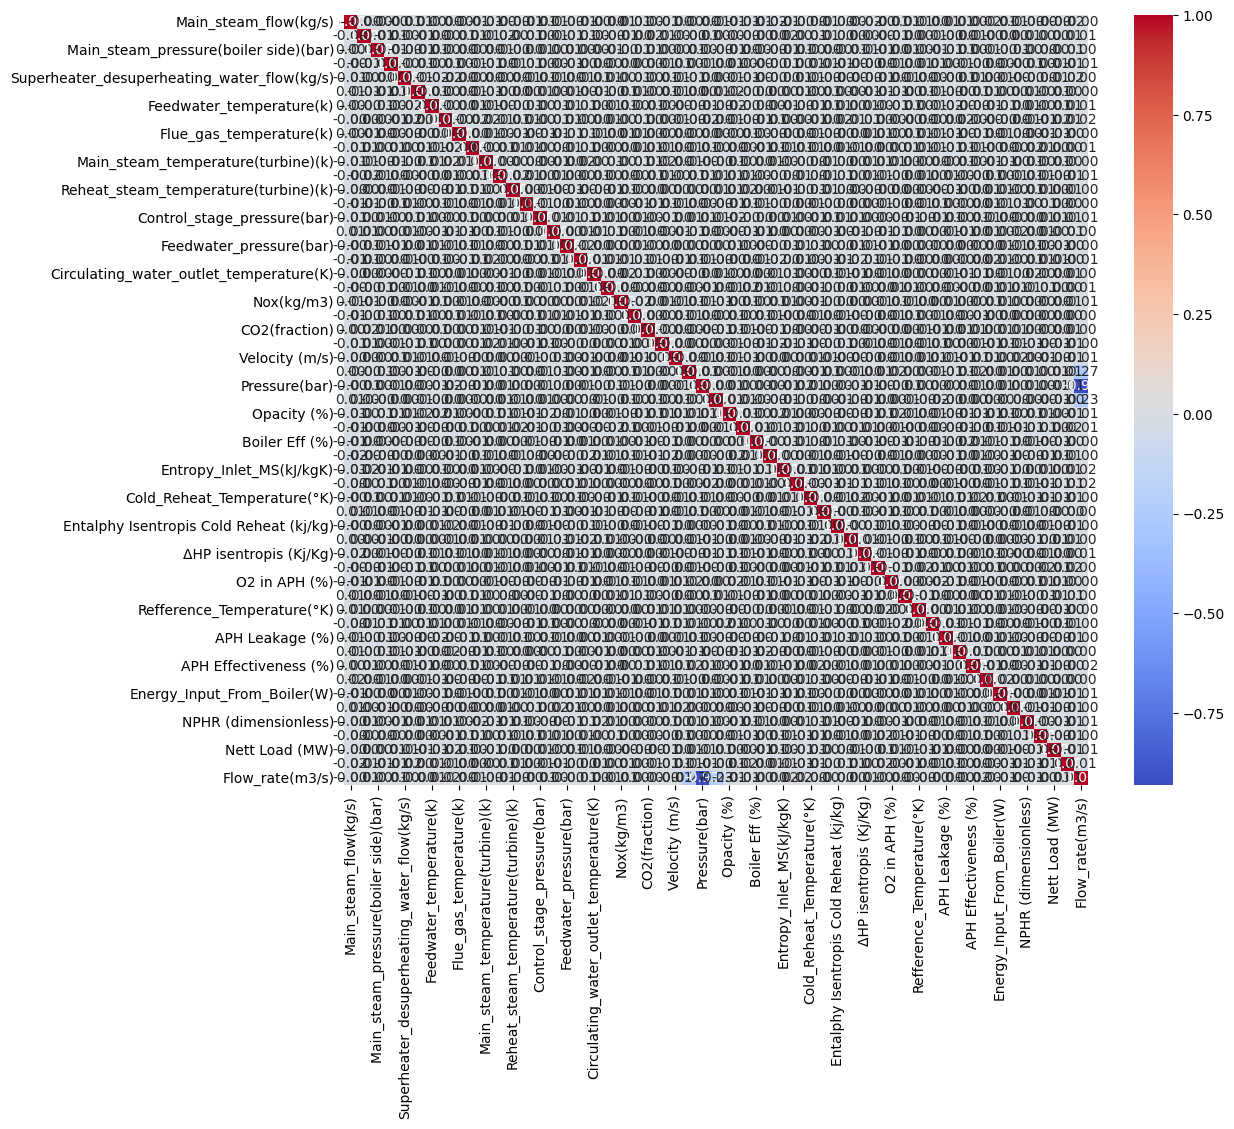

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_df = df.select_dtypes(include='number')

corr = numeric_df.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")

plt.show()

In [16]:
df["Main_steam_pressure(boiler side)(bar)"].mean() > df["Main_steam_pressure(turbine side)(bar)"].mean()

np.True_

In [17]:
df["Main_steam_temperature(boiler)(K)"].mean() > df["Main_steam_temperature(turbine)(k)"].mean()

np.True_

In [18]:
df.head()

,Timestamp,Main_steam_flow(kg/s),Main_steam_temperature(boiler)(K),Main_steam_pressure(boiler side)(bar),Reheat_steam_temperature(boiler)(k),Superheater_desuperheating_water_flow(kg/s),Reheater_desuperheating_water_flow(kg/s),Feedwater_temperature(k),Feedwater_flow(kg/s),Flue_gas_temperature(k),Boiler oxygen level (%),Main_steam_temperature(turbine)(k),Main_steam_pressure(turbine side)(bar),Reheat_steam_temperature(turbine)(k),Reheat_steam_pressure(turbine side)(bar),Control_stage_pressure(bar),High_exhaust_pressure(bar),Feedwater_pressure(bar),Condenser_vacuum(bar),Circulating_water_outlet_temperature(K),SO2(kg/m3),Nox(kg/m3),CO(kg/m3),CO2(fraction),O2 (%),Velocity (m/s),Temp.(°k),Pressure(bar),Flow rate (KNm3/h),Opacity (%),Dust(kg/m3),Boiler Eff (%),Entalphy inlet MS (kj/kg),Entropy_Inlet_MS(kJ/kgK),Cold_Reheat_Pressure(bar),Cold_Reheat_Temperature(°K),Entalphy Cold Reheat (kj/kg),Entalphy Isentropis Cold Reheat (kj/kg),ΔP aktual (Kj/Kg),ΔHP isentropis (Kj/Kg),HP Turbine eff (%),O2 in APH (%),O2 Out APH (%),Refference_Temperature(°K),Flue_Gas_in_Temperature(°K),APH Leakage (%),Corrected_Flue_Gas_Out_Temperature(°K),APH Effectiveness (%),Coal_Flow(kg/s),Energy_Input_From_Boiler(W),NTHR (dimensionless),NPHR (dimensionless),Gross Load (MW),Nett Load (MW),HHV(J/kg),Flow_rate(m3/s)
0,2022-01-01 0:00:00,231.086341,840.028717,144.460130,838.224076,24.759231,0.981668,503.713896,232.787458,399.706083,4.481404,837.605152,143.616224,838.224076,19.683226,104.000369,21.960684,156.742293,-0.923372,309.113294,0.000453,0.000179,-6.249204e-06,0.095368,6.507979,12.088643,369.376219,-0.002491,465.207243,49.698700,0.000020,93.503248,3501.326482,6.600039,21.988829,590.744075,3059.581815,2953.033708,441.744667,548.292774,80.568322,4.567314,5.118805,304.733195,629.850636,3.145248,402.693482,69.868837,46.810607,8.339530e+08,2.982272,3.189482,295.240527,279.649889,1.781547e+07,-71067.703260
1,2022-01-01 0:10:00,231.256130,840.109967,144.749073,838.027278,23.849228,1.208983,503.729426,232.892028,400.170317,4.466043,837.750973,143.904089,838.027278,19.698770,104.069275,21.976941,157.083273,-0.923320,309.150515,0.000452,0.000192,-5.098252e-06,0.095990,6.511121,12.088985,366.116537,-0.002419,465.220400,49.698697,0.000019,93.497139,3501.258556,6.599119,22.022342,590.859136,3059.761236,2952.890075,441.497320,548.368481,80.513099,4.560252,5.133138,304.862064,630.644621,3.270540,403.288310,69.786889,46.442978,8.274029e+08,2.956282,3.161891,295.522844,279.885623,1.781546e+07,-72554.071030
2,2022-01-01 0:20:00,231.078397,840.127780,145.618184,838.073357,22.291377,1.170855,503.676694,232.793891,399.805042,4.453132,837.837846,144.792306,838.073357,19.682478,103.892014,21.960066,157.989102,-0.923450,309.128460,0.000456,0.000203,-2.964671e-06,0.097203,6.550282,12.088763,364.472744,-0.002393,465.211858,49.700101,0.000016,93.497776,3500.453074,6.595631,21.988869,590.682601,3059.439246,2950.632492,441.013828,549.820583,80.212730,4.532754,5.156204,304.312509,632.635442,3.564435,403.208288,69.877082,46.052176,8.204177e+08,2.937465,3.141739,295.093870,279.289591,1.781496e+07,-73001.484895
3,2022-01-01 0:30:00,231.382185,839.899708,146.362118,838.078633,21.443933,1.010270,503.697290,232.898753,398.554809,4.419159,837.589842,145.546296,838.078633,19.707447,103.802161,21.987894,158.733250,-0.923874,309.003254,0.000458,0.000209,-1.028697e-06,0.097939,6.590462,12.082452,364.313181,-0.002399,464.969007,49.701960,0.000012,93.539664,3499.117029,6.591880,21.990132,590.341438,3058.646328,2948.599042,440.470702,550.517988,80.011260,4.485333,5.166257,304.194873,633.600331,3.894965,402.225632,70.244200,46.095449,8.209099e+08,2.941810,3.144956,295.123758,279.033867,1.780886e+07,-72755.112551
4,2022-01-01 0:40:00,231.965092,839.657266,146.258564,838.010907,22.357077,0.897292,503.770138,233.250897,396.928227,4.421077,837.267615,145.423884,838.010907,19.759375,103.934228,22.043875,158.576759,-0.924248,308.905708,0.000452,0.000213,-1.774056e-07,0.097958,6.625441,12.054904,362.590645,-0

In [19]:
"""
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(df, kind='reg', plot_kws={'line_kws':{'color':'red'}})
plt.show()"""

"\nimport seaborn as sns\nimport matplotlib.pyplot as plt\n\nsns.pairplot(df, kind='reg', plot_kws={'line_kws':{'color':'red'}})\nplt.show()"

In [20]:
pip install CoolProp

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 75.5 MB/s eta 0:00:00:00:010:01
Note: you may need to restart the kernel to use updated packages.


In [21]:
df.head()

,Timestamp,Main_steam_flow(kg/s),Main_steam_temperature(boiler)(K),Main_steam_pressure(boiler side)(bar),Reheat_steam_temperature(boiler)(k),Superheater_desuperheating_water_flow(kg/s),Reheater_desuperheating_water_flow(kg/s),Feedwater_temperature(k),Feedwater_flow(kg/s),Flue_gas_temperature(k),Boiler oxygen level (%),Main_steam_temperature(turbine)(k),Main_steam_pressure(turbine side)(bar),Reheat_steam_temperature(turbine)(k),Reheat_steam_pressure(turbine side)(bar),Control_stage_pressure(bar),High_exhaust_pressure(bar),Feedwater_pressure(bar),Condenser_vacuum(bar),Circulating_water_outlet_temperature(K),SO2(kg/m3),Nox(kg/m3),CO(kg/m3),CO2(fraction),O2 (%),Velocity (m/s),Temp.(°k),Pressure(bar),Flow rate (KNm3/h),Opacity (%),Dust(kg/m3),Boiler Eff (%),Entalphy inlet MS (kj/kg),Entropy_Inlet_MS(kJ/kgK),Cold_Reheat_Pressure(bar),Cold_Reheat_Temperature(°K),Entalphy Cold Reheat (kj/kg),Entalphy Isentropis Cold Reheat (kj/kg),ΔP aktual (Kj/Kg),ΔHP isentropis (Kj/Kg),HP Turbine eff (%),O2 in APH (%),O2 Out APH (%),Refference_Temperature(°K),Flue_Gas_in_Temperature(°K),APH Leakage (%),Corrected_Flue_Gas_Out_Temperature(°K),APH Effectiveness (%),Coal_Flow(kg/s),Energy_Input_From_Boiler(W),NTHR (dimensionless),NPHR (dimensionless),Gross Load (MW),Nett Load (MW),HHV(J/kg),Flow_rate(m3/s)
0,2022-01-01 0:00:00,231.086341,840.028717,144.460130,838.224076,24.759231,0.981668,503.713896,232.787458,399.706083,4.481404,837.605152,143.616224,838.224076,19.683226,104.000369,21.960684,156.742293,-0.923372,309.113294,0.000453,0.000179,-6.249204e-06,0.095368,6.507979,12.088643,369.376219,-0.002491,465.207243,49.698700,0.000020,93.503248,3501.326482,6.600039,21.988829,590.744075,3059.581815,2953.033708,441.744667,548.292774,80.568322,4.567314,5.118805,304.733195,629.850636,3.145248,402.693482,69.868837,46.810607,8.339530e+08,2.982272,3.189482,295.240527,279.649889,1.781547e+07,-71067.703260
1,2022-01-01 0:10:00,231.256130,840.109967,144.749073,838.027278,23.849228,1.208983,503.729426,232.892028,400.170317,4.466043,837.750973,143.904089,838.027278,19.698770,104.069275,21.976941,157.083273,-0.923320,309.150515,0.000452,0.000192,-5.098252e-06,0.095990,6.511121,12.088985,366.116537,-0.002419,465.220400,49.698697,0.000019,93.497139,3501.258556,6.599119,22.022342,590.859136,3059.761236,2952.890075,441.497320,548.368481,80.513099,4.560252,5.133138,304.862064,630.644621,3.270540,403.288310,69.786889,46.442978,8.274029e+08,2.956282,3.161891,295.522844,279.885623,1.781546e+07,-72554.071030
2,2022-01-01 0:20:00,231.078397,840.127780,145.618184,838.073357,22.291377,1.170855,503.676694,232.793891,399.805042,4.453132,837.837846,144.792306,838.073357,19.682478,103.892014,21.960066,157.989102,-0.923450,309.128460,0.000456,0.000203,-2.964671e-06,0.097203,6.550282,12.088763,364.472744,-0.002393,465.211858,49.700101,0.000016,93.497776,3500.453074,6.595631,21.988869,590.682601,3059.439246,2950.632492,441.013828,549.820583,80.212730,4.532754,5.156204,304.312509,632.635442,3.564435,403.208288,69.877082,46.052176,8.204177e+08,2.937465,3.141739,295.093870,279.289591,1.781496e+07,-73001.484895
3,2022-01-01 0:30:00,231.382185,839.899708,146.362118,838.078633,21.443933,1.010270,503.697290,232.898753,398.554809,4.419159,837.589842,145.546296,838.078633,19.707447,103.802161,21.987894,158.733250,-0.923874,309.003254,0.000458,0.000209,-1.028697e-06,0.097939,6.590462,12.082452,364.313181,-0.002399,464.969007,49.701960,0.000012,93.539664,3499.117029,6.591880,21.990132,590.341438,3058.646328,2948.599042,440.470702,550.517988,80.011260,4.485333,5.166257,304.194873,633.600331,3.894965,402.225632,70.244200,46.095449,8.209099e+08,2.941810,3.144956,295.123758,279.033867,1.780886e+07,-72755.112551
4,2022-01-01 0:40:00,231.965092,839.657266,146.258564,838.010907,22.357077,0.897292,503.770138,233.250897,396.928227,4.421077,837.267615,145.423884,838.010907,19.759375,103.934228,22.043875,158.576759,-0.924248,308.905708,0.000452,0.000213,-1.774056e-07,0.097958,6.625441,12.054904,362.590645,-0

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50091 entries, 0 to 50090
Data columns (total 56 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   Timestamp                                    50091 non-null  object 
 1   Main_steam_flow(kg/s)                        50091 non-null  float64
 2   Main_steam_temperature(boiler)(K)            50091 non-null  float64
 3   Main_steam_pressure(boiler side)(bar)        50091 non-null  float64
 4   Reheat_steam_temperature(boiler)(k)          50091 non-null  float64
 5   Superheater_desuperheating_water_flow(kg/s)  50091 non-null  float64
 6   Reheater_desuperheating_water_flow(kg/s)     50091 non-null  float64
 7   Feedwater_temperature(k)                     50091 non-null  float64
 8   Feedwater_flow(kg/s)                         50091 non-null  float64
 9   Flue_gas_temperature(k)                      50091 non-null  float64
 10

In [23]:
import CoolProp.CoolProp as CP

from pint import UnitRegistry

ureg = UnitRegistry()

df["Pressure(Pa)"] = df["Pressure(bar)"].apply(
    lambda x: (x * ureg.bar).to(ureg.Pa).magnitude
)
#df["RH_fraction"] = df["RH(%)"] / 100

In [24]:
df.head()

,Timestamp,Main_steam_flow(kg/s),Main_steam_temperature(boiler)(K),Main_steam_pressure(boiler side)(bar),Reheat_steam_temperature(boiler)(k),Superheater_desuperheating_water_flow(kg/s),Reheater_desuperheating_water_flow(kg/s),Feedwater_temperature(k),Feedwater_flow(kg/s),Flue_gas_temperature(k),Boiler oxygen level (%),Main_steam_temperature(turbine)(k),Main_steam_pressure(turbine side)(bar),Reheat_steam_temperature(turbine)(k),Reheat_steam_pressure(turbine side)(bar),Control_stage_pressure(bar),High_exhaust_pressure(bar),Feedwater_pressure(bar),Condenser_vacuum(bar),Circulating_water_outlet_temperature(K),SO2(kg/m3),Nox(kg/m3),CO(kg/m3),CO2(fraction),O2 (%),Velocity (m/s),Temp.(°k),Pressure(bar),Flow rate (KNm3/h),Opacity (%),Dust(kg/m3),Boiler Eff (%),Entalphy inlet MS (kj/kg),Entropy_Inlet_MS(kJ/kgK),Cold_Reheat_Pressure(bar),Cold_Reheat_Temperature(°K),Entalphy Cold Reheat (kj/kg),Entalphy Isentropis Cold Reheat (kj/kg),ΔP aktual (Kj/Kg),ΔHP isentropis (Kj/Kg),HP Turbine eff (%),O2 in APH (%),O2 Out APH (%),Refference_Temperature(°K),Flue_Gas_in_Temperature(°K),APH Leakage (%),Corrected_Flue_Gas_Out_Temperature(°K),APH Effectiveness (%),Coal_Flow(kg/s),Energy_Input_From_Boiler(W),NTHR (dimensionless),NPHR (dimensionless),Gross Load (MW),Nett Load (MW),HHV(J/kg),Flow_rate(m3/s),Pressure(Pa)
0,2022-01-01 0:00:00,231.086341,840.028717,144.460130,838.224076,24.759231,0.981668,503.713896,232.787458,399.706083,4.481404,837.605152,143.616224,838.224076,19.683226,104.000369,21.960684,156.742293,-0.923372,309.113294,0.000453,0.000179,-6.249204e-06,0.095368,6.507979,12.088643,369.376219,-0.002491,465.207243,49.698700,0.000020,93.503248,3501.326482,6.600039,21.988829,590.744075,3059.581815,2953.033708,441.744667,548.292774,80.568322,4.567314,5.118805,304.733195,629.850636,3.145248,402.693482,69.868837,46.810607,8.339530e+08,2.982272,3.189482,295.240527,279.649889,1.781547e+07,-71067.703260,-249.147209
1,2022-01-01 0:10:00,231.256130,840.109967,144.749073,838.027278,23.849228,1.208983,503.729426,232.892028,400.170317,4.466043,837.750973,143.904089,838.027278,19.698770,104.069275,21.976941,157.083273,-0.923320,309.150515,0.000452,0.000192,-5.098252e-06,0.095990,6.511121,12.088985,366.116537,-0.002419,465.220400,49.698697,0.000019,93.497139,3501.258556,6.599119,22.022342,590.859136,3059.761236,2952.890075,441.497320,548.368481,80.513099,4.560252,5.133138,304.862064,630.644621,3.270540,403.288310,69.786889,46.442978,8.274029e+08,2.956282,3.161891,295.522844,279.885623,1.781546e+07,-72554.071030,-241.896295
2,2022-01-01 0:20:00,231.078397,840.127780,145.618184,838.073357,22.291377,1.170855,503.676694,232.793891,399.805042,4.453132,837.837846,144.792306,838.073357,19.682478,103.892014,21.960066,157.989102,-0.923450,309.128460,0.000456,0.000203,-2.964671e-06,0.097203,6.550282,12.088763,364.472744,-0.002393,465.211858,49.700101,0.000016,93.497776,3500.453074,6.595631,21.988869,590.682601,3059.439246,2950.632492,441.013828,549.820583,80.212730,4.532754,5.156204,304.312509,632.635442,3.564435,403.208288,69.877082,46.052176,8.204177e+08,2.937465,3.141739,295.093870,279.289591,1.781496e+07,-73001.484895,-239.329947
3,2022-01-01 0:30:00,231.382185,839.899708,146.362118,838.078633,21.443933,1.010270,503.697290,232.898753,398.554809,4.419159,837.589842,145.546296,838.078633,19.707447,103.802161,21.987894,158.733250,-0.923874,309.003254,0.000458,0.000209,-1.028697e-06,0.097939,6.590462,12.082452,364.313181,-0.002399,464.969007,49.701960,0.000012,93.539664,3499.117029,6.591880,21.990132,590.341438,3058.646328,2948.599042,440.470702,550.517988,80.011260,4.485333,5.166257,304.194873,633.600331,3.894965,402.225632,70.244200,46.095449,8.209099e+08,2.941810,3.144956,295.123758,279.033867,1.780886e+07,-72755.112551,-239.909961
4,2022-01-01 0:40:00,231.965092,839.657266,146.258564,838.010907,22.357077,0.897292,503.770138,233.250897,396.928227,4.421077,837.267615,145.423884,838.010907,19.759375,103.934228,22.043875,158.576759,-0.924248,308.905708,0.000452,0.0

In [25]:
"""
[ BOILER ] ---> (Long Pipes: Drops Pressure & Temp) ---> [ TURBINE ]

    |                                                          |
    V                                                          V
Use for: Boiler Efficiency                                Use for: Power Generated,
& Heat Added from Fuel                                    Turbine Work, & Plant Efficiency
"""

'\n[ BOILER ] ---> (Long Pipes: Drops Pressure & Temp) ---> [ TURBINE ]\n\n    |                                                          |\n    V                                                          V\nUse for: Boiler Efficiency                                Use for: Power Generated,\n& Heat Added from Fuel                                    Turbine Work, & Plant Efficiency\n'

In [26]:
"""
df.rename(columns={
    "Main_steam_flow(kg/s)": "m_dot_steam(kg/s)",
    #"Main_steam_temperature(boiler)(K)": "T1(K)",
    #"Main_steam_pressure(boiler side)(bar)": "p1(bar)",

    "Main_steam_temperature(turbine)(k)":"T1(k)",
    "Main_steam_pressure(turbine side)(bar)":"p1(bar)",
    
    
    "Reheat_steam_temperature(boiler)(k)":"T3(k)",
    "Reheater_desuperheating_water_flow(kg/s)":"m_dot_rh(kg/s)",
    
    "Feedwater_temperature(k)":"T_fw(k)",
    "Feedwater_flow(kg/s)":"m_dot_fw(kg/s)",
    #"Flue_gas_temperature(k)": 
}, inplace=True)
"""

'\ndf.rename(columns={\n    "Main_steam_flow(kg/s)": "m_dot_steam(kg/s)",\n    #"Main_steam_temperature(boiler)(K)": "T1(K)",\n    #"Main_steam_pressure(boiler side)(bar)": "p1(bar)",\n\n    "Main_steam_temperature(turbine)(k)":"T1(k)",\n    "Main_steam_pressure(turbine side)(bar)":"p1(bar)",\n    \n    \n    "Reheat_steam_temperature(boiler)(k)":"T3(k)",\n    "Reheater_desuperheating_water_flow(kg/s)":"m_dot_rh(kg/s)",\n    \n    "Feedwater_temperature(k)":"T_fw(k)",\n    "Feedwater_flow(kg/s)":"m_dot_fw(kg/s)",\n    #"Flue_gas_temperature(k)": \n}, inplace=True)\n'

In [27]:
df.head()

,Timestamp,Main_steam_flow(kg/s),Main_steam_temperature(boiler)(K),Main_steam_pressure(boiler side)(bar),Reheat_steam_temperature(boiler)(k),Superheater_desuperheating_water_flow(kg/s),Reheater_desuperheating_water_flow(kg/s),Feedwater_temperature(k),Feedwater_flow(kg/s),Flue_gas_temperature(k),Boiler oxygen level (%),Main_steam_temperature(turbine)(k),Main_steam_pressure(turbine side)(bar),Reheat_steam_temperature(turbine)(k),Reheat_steam_pressure(turbine side)(bar),Control_stage_pressure(bar),High_exhaust_pressure(bar),Feedwater_pressure(bar),Condenser_vacuum(bar),Circulating_water_outlet_temperature(K),SO2(kg/m3),Nox(kg/m3),CO(kg/m3),CO2(fraction),O2 (%),Velocity (m/s),Temp.(°k),Pressure(bar),Flow rate (KNm3/h),Opacity (%),Dust(kg/m3),Boiler Eff (%),Entalphy inlet MS (kj/kg),Entropy_Inlet_MS(kJ/kgK),Cold_Reheat_Pressure(bar),Cold_Reheat_Temperature(°K),Entalphy Cold Reheat (kj/kg),Entalphy Isentropis Cold Reheat (kj/kg),ΔP aktual (Kj/Kg),ΔHP isentropis (Kj/Kg),HP Turbine eff (%),O2 in APH (%),O2 Out APH (%),Refference_Temperature(°K),Flue_Gas_in_Temperature(°K),APH Leakage (%),Corrected_Flue_Gas_Out_Temperature(°K),APH Effectiveness (%),Coal_Flow(kg/s),Energy_Input_From_Boiler(W),NTHR (dimensionless),NPHR (dimensionless),Gross Load (MW),Nett Load (MW),HHV(J/kg),Flow_rate(m3/s),Pressure(Pa)
0,2022-01-01 0:00:00,231.086341,840.028717,144.460130,838.224076,24.759231,0.981668,503.713896,232.787458,399.706083,4.481404,837.605152,143.616224,838.224076,19.683226,104.000369,21.960684,156.742293,-0.923372,309.113294,0.000453,0.000179,-6.249204e-06,0.095368,6.507979,12.088643,369.376219,-0.002491,465.207243,49.698700,0.000020,93.503248,3501.326482,6.600039,21.988829,590.744075,3059.581815,2953.033708,441.744667,548.292774,80.568322,4.567314,5.118805,304.733195,629.850636,3.145248,402.693482,69.868837,46.810607,8.339530e+08,2.982272,3.189482,295.240527,279.649889,1.781547e+07,-71067.703260,-249.147209
1,2022-01-01 0:10:00,231.256130,840.109967,144.749073,838.027278,23.849228,1.208983,503.729426,232.892028,400.170317,4.466043,837.750973,143.904089,838.027278,19.698770,104.069275,21.976941,157.083273,-0.923320,309.150515,0.000452,0.000192,-5.098252e-06,0.095990,6.511121,12.088985,366.116537,-0.002419,465.220400,49.698697,0.000019,93.497139,3501.258556,6.599119,22.022342,590.859136,3059.761236,2952.890075,441.497320,548.368481,80.513099,4.560252,5.133138,304.862064,630.644621,3.270540,403.288310,69.786889,46.442978,8.274029e+08,2.956282,3.161891,295.522844,279.885623,1.781546e+07,-72554.071030,-241.896295
2,2022-01-01 0:20:00,231.078397,840.127780,145.618184,838.073357,22.291377,1.170855,503.676694,232.793891,399.805042,4.453132,837.837846,144.792306,838.073357,19.682478,103.892014,21.960066,157.989102,-0.923450,309.128460,0.000456,0.000203,-2.964671e-06,0.097203,6.550282,12.088763,364.472744,-0.002393,465.211858,49.700101,0.000016,93.497776,3500.453074,6.595631,21.988869,590.682601,3059.439246,2950.632492,441.013828,549.820583,80.212730,4.532754,5.156204,304.312509,632.635442,3.564435,403.208288,69.877082,46.052176,8.204177e+08,2.937465,3.141739,295.093870,279.289591,1.781496e+07,-73001.484895,-239.329947
3,2022-01-01 0:30:00,231.382185,839.899708,146.362118,838.078633,21.443933,1.010270,503.697290,232.898753,398.554809,4.419159,837.589842,145.546296,838.078633,19.707447,103.802161,21.987894,158.733250,-0.923874,309.003254,0.000458,0.000209,-1.028697e-06,0.097939,6.590462,12.082452,364.313181,-0.002399,464.969007,49.701960,0.000012,93.539664,3499.117029,6.591880,21.990132,590.341438,3058.646328,2948.599042,440.470702,550.517988,80.011260,4.485333,5.166257,304.194873,633.600331,3.894965,402.225632,70.244200,46.095449,8.209099e+08,2.941810,3.144956,295.123758,279.033867,1.780886e+07,-72755.112551,-239.909961
4,2022-01-01 0:40:00,231.965092,839.657266,146.258564,838.010907,22.357077,0.897292,503.770138,233.250897,396.928227,4.421077,837.267615,145.423884,838.010907,19.759375,103.934228,22.043875,158.576759,-0.924248,308.905708,0.000452,0.0

In [28]:
"""
BOILER / MAIN STEAM : -> its outlet is 'STATE 1'
HP TURBINE: STATE 1 → STATE 2
REHEATER: STATE 2 → STATE 3
SECOND TURBINE: STATE 3 → STATE 4


"""

"\nBOILER / MAIN STEAM : -> its outlet is 'STATE 1'\nHP TURBINE: STATE 1 → STATE 2\nREHEATER: STATE 2 → STATE 3\nSECOND TURBINE: STATE 3 → STATE 4\n\n\n"

In [29]:
RENAME_MAP = {

    # STATE 1 — HP TURBINE INLET / BOILER OUTLET
    "Main_steam_temperature(turbine)(k)": "T1(K)",
    "Main_steam_pressure(turbine side)(bar)": "P1(bar)",
    "Main_steam_flow(kg/s)": "m1_dot_steam(kg/s)",

    # STATE 2 — HP TURBINE OUTLET
    # COLD REHEAT
    "Cold_Reheat_Temperature(°K)": "T2(K)",
    "Cold_Reheat_Pressure(bar)": "P2(bar)",
    "Entalphy Cold Reheat (kj/kg)": "h2(kJ/kg)",
    "Entalphy Isentropis Cold Reheat (kj/kg)": "h2s(kJ/kg)",

    # STATE 3 — LP TURBINE INLET
    # AFTER REHEATER
    "Reheat_steam_temperature(turbine)(k)": "T3(K)",
    "Reheat_steam_pressure(turbine side)(bar)": "P3(bar)",

    # STATE 8 — FEEDWATER / BOILER INLET
    "Feedwater_temperature(k)": "T8(K)",
    "Feedwater_pressure(bar)": "P8(bar)",
    "Feedwater_flow(kg/s)": "m8_dot_water(kg/s)",

    "Energy_Input_From_Boiler(W)": "Q_boiler_in(W)",

    "Condenser_vacuum(bar)": "P_Cond_Vacuum(bar)",
}

df = df.rename(columns=RENAME_MAP)

In [30]:
df.head()

,Timestamp,m1_dot_steam(kg/s),Main_steam_temperature(boiler)(K),Main_steam_pressure(boiler side)(bar),Reheat_steam_temperature(boiler)(k),Superheater_desuperheating_water_flow(kg/s),Reheater_desuperheating_water_flow(kg/s),T8(K),m8_dot_water(kg/s),Flue_gas_temperature(k),Boiler oxygen level (%),T1(K),P1(bar),T3(K),P3(bar),Control_stage_pressure(bar),High_exhaust_pressure(bar),P8(bar),P_Cond_Vacuum(bar),Circulating_water_outlet_temperature(K),SO2(kg/m3),Nox(kg/m3),CO(kg/m3),CO2(fraction),O2 (%),Velocity (m/s),Temp.(°k),Pressure(bar),Flow rate (KNm3/h),Opacity (%),Dust(kg/m3),Boiler Eff (%),Entalphy inlet MS (kj/kg),Entropy_Inlet_MS(kJ/kgK),P2(bar),T2(K),h2(kJ/kg),h2s(kJ/kg),ΔP aktual (Kj/Kg),ΔHP isentropis (Kj/Kg),HP Turbine eff (%),O2 in APH (%),O2 Out APH (%),Refference_Temperature(°K),Flue_Gas_in_Temperature(°K),APH Leakage (%),Corrected_Flue_Gas_Out_Temperature(°K),APH Effectiveness (%),Coal_Flow(kg/s),Q_boiler_in(W),NTHR (dimensionless),NPHR (dimensionless),Gross Load (MW),Nett Load (MW),HHV(J/kg),Flow_rate(m3/s),Pressure(Pa)
0,2022-01-01 0:00:00,231.086341,840.028717,144.460130,838.224076,24.759231,0.981668,503.713896,232.787458,399.706083,4.481404,837.605152,143.616224,838.224076,19.683226,104.000369,21.960684,156.742293,-0.923372,309.113294,0.000453,0.000179,-6.249204e-06,0.095368,6.507979,12.088643,369.376219,-0.002491,465.207243,49.698700,0.000020,93.503248,3501.326482,6.600039,21.988829,590.744075,3059.581815,2953.033708,441.744667,548.292774,80.568322,4.567314,5.118805,304.733195,629.850636,3.145248,402.693482,69.868837,46.810607,8.339530e+08,2.982272,3.189482,295.240527,279.649889,1.781547e+07,-71067.703260,-249.147209
1,2022-01-01 0:10:00,231.256130,840.109967,144.749073,838.027278,23.849228,1.208983,503.729426,232.892028,400.170317,4.466043,837.750973,143.904089,838.027278,19.698770,104.069275,21.976941,157.083273,-0.923320,309.150515,0.000452,0.000192,-5.098252e-06,0.095990,6.511121,12.088985,366.116537,-0.002419,465.220400,49.698697,0.000019,93.497139,3501.258556,6.599119,22.022342,590.859136,3059.761236,2952.890075,441.497320,548.368481,80.513099,4.560252,5.133138,304.862064,630.644621,3.270540,403.288310,69.786889,46.442978,8.274029e+08,2.956282,3.161891,295.522844,279.885623,1.781546e+07,-72554.071030,-241.896295
2,2022-01-01 0:20:00,231.078397,840.127780,145.618184,838.073357,22.291377,1.170855,503.676694,232.793891,399.805042,4.453132,837.837846,144.792306,838.073357,19.682478,103.892014,21.960066,157.989102,-0.923450,309.128460,0.000456,0.000203,-2.964671e-06,0.097203,6.550282,12.088763,364.472744,-0.002393,465.211858,49.700101,0.000016,93.497776,3500.453074,6.595631,21.988869,590.682601,3059.439246,2950.632492,441.013828,549.820583,80.212730,4.532754,5.156204,304.312509,632.635442,3.564435,403.208288,69.877082,46.052176,8.204177e+08,2.937465,3.141739,295.093870,279.289591,1.781496e+07,-73001.484895,-239.329947
3,2022-01-01 0:30:00,231.382185,839.899708,146.362118,838.078633,21.443933,1.010270,503.697290,232.898753,398.554809,4.419159,837.589842,145.546296,838.078633,19.707447,103.802161,21.987894,158.733250,-0.923874,309.003254,0.000458,0.000209,-1.028697e-06,0.097939,6.590462,12.082452,364.313181,-0.002399,464.969007,49.701960,0.000012,93.539664,3499.117029,6.591880,21.990132,590.341438,3058.646328,2948.599042,440.470702,550.517988,80.011260,4.485333,5.166257,304.194873,633.600331,3.894965,402.225632,70.244200,46.095449,8.209099e+08,2.941810,3.144956,295.123758,279.033867,1.780886e+07,-72755.112551,-239.909961
4,2022-01-01 0:40:00,231.965092,839.657266,146.258564,838.010907,22.357077,0.897292,503.770138,233.250897,396.928227,4.421077,837.267615,145.423884,838.010907,19.759375,103.934228,22.043875,158.576759,-0.924248,308.905708,0.000452,0.000213,-1.774056e-07,0.097958,6.625441,12.054904,362.590645,-0.002358,463.908869,49.703167,0.000009,93.627757,3498.574566,6.591538,22.037707,590.221086,3058.244375,2948.915782,440.330192,549.658784,80.110358,4.469492,5.173391,304.979867,631.363968,4.027866,400.629518,7

In [31]:
!pip install iapws

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.4/117.4 kB 3.8 MB/s eta 0:00:00


In [32]:
from iapws import IAPWS97
import pint

ureg = pint.UnitRegistry()
Q_ = ureg.Quantity

# ------------------------------------------------------------------
# State 3 -> State 4  (L.P.T inlet -> L.P.T exhaust / condenser inlet)
# IAPWS97 needs: P in MPa, T in K, h in kJ/kg, s in kJ/(kg*K)
# ------------------------------------------------------------------

# --- inputs, in whatever units your data actually uses ---
T3 = Q_(810.0, "K")
P3 = Q_(40.0, "bar")
P_cond = Q_(0.10, "bar")     # = P4, condenser pressure (assumed already absolute)

# --- convert once, with pint, no manual factors ---
T3_K = T3.to("K").magnitude
P3_MPa = P3.to("MPa").magnitude
P4_MPa = P_cond.to("MPa").magnitude

# --- state 3 ---
st3 = IAPWS97(P=P3_MPa, T=T3_K)
h3, s3 = st3.h, st3.s

# --- state 4, isentropic (s4 = s3), at condenser pressure ---
st4 = IAPWS97(P=P4_MPa, s=s3)

P4_bar = Q_(P4_MPa, "MPa").to("bar").magnitude  # convert back for display, with pint

print(f"h3    = {h3:.2f} kJ/kg")
print(f"s3    = {s3:.4f} kJ/kg-K")
print(f"T4    = {st4.T:.2f} K")
print(f"P4    = {P4_bar:.4f} bar")
print(f"h4    = {st4.h:.2f} kJ/kg")
print(f"x4    = {st4.x:.4f}   (vapor quality)")

# --- if you have/assume an LP turbine efficiency instead of ideal ---
eta_LPT = 0.88
h4s = st4.h                       # isentropic enthalpy just computed
h4_real = h3 - eta_LPT * (h3 - h4s)
st4_real = IAPWS97(P=P4_MPa, h=h4_real)

print("\nWith LP turbine efficiency = 0.88:")
print(f"h4    = {st4_real.h:.2f} kJ/kg")
print(f"T4    = {st4_real.T:.2f} K")
print(f"x4    = {st4_real.x:.4f}")

h3    = 3530.13 kJ/kg
s3    = 7.1984 kJ/kg-K
T4    = 318.96 K
P4    = 0.1000 bar
h4    = 2280.72 kJ/kg
x4    = 0.8733   (vapor quality)

With LP turbine efficiency = 0.88:
h4    = 2430.65 kJ/kg
T4    = 318.96 K
x4    = 0.9359


In [33]:
from iapws import IAPWS97
import pint
import numpy as np

ureg = pint.UnitRegistry()
Q_ = ureg.Quantity

# State 3: LP turbine inlet

h3_list = []
s3_list = []

for T3_value, P3_value in zip(
    df["T3(K)"],
    df["P3(bar)"]
):

    try:
        T3 = Q_(T3_value, "K")
        P3 = Q_(P3_value, "bar")

        T3_K = T3.to("K").magnitude
        P3_MPa = P3.to("MPa").magnitude

        st3 = IAPWS97(
            T=T3_K,
            P=P3_MPa
        )

        h3_list.append(st3.h)
        s3_list.append(st3.s)

    except Exception:
        h3_list.append(np.nan)
        s3_list.append(np.nan)

df["h3(kJ/kg)"] = h3_list
df["s3(kJ/kgK)"] = s3_list

In [34]:
P_atm = Q_(1.01325, "bar")

df["P4(bar)"] = (
    P_atm.magnitude
    + df["P_Cond_Vacuum(bar)"]
)

In [35]:
h4s_list = []
T4s_list = []
x4s_list = []

for P4_value, s3_value in zip(
    df["P4(bar)"],
    df["s3(kJ/kgK)"]
):

    try:
        P4 = Q_(P4_value, "bar")

        P4_MPa = P4.to("MPa").magnitude

        # Isentropic LP turbine outlet
        st4s = IAPWS97(
            P=P4_MPa,
            s=s3_value
        )

        h4s_list.append(st4s.h)
        T4s_list.append(st4s.T)
        x4s_list.append(st4s.x)

    except Exception:
        h4s_list.append(np.nan)
        T4s_list.append(np.nan)
        x4s_list.append(np.nan)

df["h4s(kJ/kg)"] = h4s_list
df["T4s(K)"] = T4s_list
df["x4s"] = x4s_list

In [36]:
df.head()

,Timestamp,m1_dot_steam(kg/s),Main_steam_temperature(boiler)(K),Main_steam_pressure(boiler side)(bar),Reheat_steam_temperature(boiler)(k),Superheater_desuperheating_water_flow(kg/s),Reheater_desuperheating_water_flow(kg/s),T8(K),m8_dot_water(kg/s),Flue_gas_temperature(k),Boiler oxygen level (%),T1(K),P1(bar),T3(K),P3(bar),Control_stage_pressure(bar),High_exhaust_pressure(bar),P8(bar),P_Cond_Vacuum(bar),Circulating_water_outlet_temperature(K),SO2(kg/m3),Nox(kg/m3),CO(kg/m3),CO2(fraction),O2 (%),Velocity (m/s),Temp.(°k),Pressure(bar),Flow rate (KNm3/h),Opacity (%),Dust(kg/m3),Boiler Eff (%),Entalphy inlet MS (kj/kg),Entropy_Inlet_MS(kJ/kgK),P2(bar),T2(K),h2(kJ/kg),h2s(kJ/kg),ΔP aktual (Kj/Kg),ΔHP isentropis (Kj/Kg),HP Turbine eff (%),O2 in APH (%),O2 Out APH (%),Refference_Temperature(°K),Flue_Gas_in_Temperature(°K),APH Leakage (%),Corrected_Flue_Gas_Out_Temperature(°K),APH Effectiveness (%),Coal_Flow(kg/s),Q_boiler_in(W),NTHR (dimensionless),NPHR (dimensionless),Gross Load (MW),Nett Load (MW),HHV(J/kg),Flow_rate(m3/s),Pressure(Pa),h3(kJ/kg),s3(kJ/kgK),P4(bar),h4s(kJ/kg),T4s(K),x4s
0,2022-01-01 0:00:00,231.086341,840.028717,144.460130,838.224076,24.759231,0.981668,503.713896,232.787458,399.706083,4.481404,837.605152,143.616224,838.224076,19.683226,104.000369,21.960684,156.742293,-0.923372,309.113294,0.000453,0.000179,-6.249204e-06,0.095368,6.507979,12.088643,369.376219,-0.002491,465.207243,49.698700,0.000020,93.503248,3501.326482,6.600039,21.988829,590.744075,3059.581815,2953.033708,441.744667,548.292774,80.568322,4.567314,5.118805,304.733195,629.850636,3.145248,402.693482,69.868837,46.810607,8.339530e+08,2.982272,3.189482,295.240527,279.649889,1.781547e+07,-71067.703260,-249.147209,3612.748577,7.620375,0.089878,2400.838696,316.885605,0.925172
1,2022-01-01 0:10:00,231.256130,840.109967,144.749073,838.027278,23.849228,1.208983,503.729426,232.892028,400.170317,4.466043,837.750973,143.904089,838.027278,19.698770,104.069275,21.976941,157.083273,-0.923320,309.150515,0.000452,0.000192,-5.098252e-06,0.095990,6.511121,12.088985,366.116537,-0.002419,465.220400,49.698697,0.000019,93.497139,3501.258556,6.599119,22.022342,590.859136,3059.761236,2952.890075,441.497320,548.368481,80.513099,4.560252,5.133138,304.862064,630.644621,3.270540,403.288310,69.786889,46.442978,8.274029e+08,2.956282,3.161891,295.522844,279.885623,1.781546e+07,-72554.071030,-241.896295,3612.295843,7.619475,0.089930,2400.631838,316.896824,0.925077
2,2022-01-01 0:20:00,231.078397,840.127780,145.618184,838.073357,22.291377,1.170855,503.676694,232.793891,399.805042,4.453132,837.837846,144.792306,838.073357,19.682478,103.892014,21.960066,157.989102,-0.923450,309.128460,0.000456,0.000203,-2.964671e-06,0.097203,6.550282,12.088763,364.472744,-0.002393,465.211858,49.700101,0.000016,93.497776,3500.453074,6.595631,21.988869,590.682601,3059.439246,2950.632492,441.013828,549.820583,80.212730,4.532754,5.156204,304.312509,632.635442,3.564435,403.208288,69.877082,46.052176,8.204177e+08,2.937465,3.141739,295.093870,279.289591,1.781496e+07,-73001.484895,-239.329947,3612.412978,7.619992,0.089800,2400.601438,316.869049,0.925087
3,2022-01-01 0:30:00,231.382185,839.899708,146.362118,838.078633,21.443933,1.010270,503.697290,232.898753,398.554809,4.419159,837.589842,145.546296,838.078633,19.707447,103.802161,21.987894,158.733250,-0.923874,309.003254,0.000458,0.000209,-1.028697e-06,0.097939,6.590462,12.082452,364.313181,-0.002399,464.969007,49.701960,0.000012,93.539664,3499.117029,6.591880,21.990132,590.341438,3058.646328,2948.599042,440.470702,550.517988,80.011260,4.485333,5.166257,304.194873,633.600331,3.894965,402.225632,70.244200,46.095449,8.209099e+08,2.941810,3.144956,295.123758,279.033867,1.780886e+07,-72755.112551,-239.909961,3612.402786,7.619401,0.089376,2399.775351,316.777772,0.924817
4,2022-01-01 0:40:00,231.965092,839.657266,146.258564,838.010907,22.357077,0.897292,503.770138,233.250897,396.928227,4.421077,837.267615,145.423884,838.010907,19.759375,103.934228,22.043875,158.576759,-0

In [37]:
from iapws import IAPWS97
import numpy as np

T5_list = []
h5_list = []
s5_list = []

for P5_value in df["P4(bar)"]:

    try:
        # P5 = P4
        P5 = P5_value * ureg.bar

        # Pint: bar → MPa
        P5_MPa = P5.to("MPa").magnitude

        # Saturated liquid: x = 0
        state5 = IAPWS97(
            P=P5_MPa,
            x=0
        )

        T5_list.append(state5.T)
        h5_list.append(state5.h)
        s5_list.append(state5.s)

    except Exception:

        T5_list.append(np.nan)
        h5_list.append(np.nan)
        s5_list.append(np.nan)

df["T5(K)"] = T5_list
df["h5(kJ/kg)"] = h5_list
df["s5(kJ/kgK)"] = s5_list

In [ ]:
h6s_list = []
T6s_list = []
s6s_list = []

for P6_value, s5_value in zip(
    df["P2(bar)"],
    df["s5(kJ/kgK)"]
):
    try:
        # P6 = P2 = P3 = OFWH pressure
        P6 = P6_value * ureg.bar
        P6_MPa = P6.to("MPa").magnitude

        # Ideal pump:
        # s6s = s5
        state6s = IAPWS97(
            P=P6_MPa,
            s=s5_value
        )

        h6s_list.append(state6s.h)
        T6s_list.append(state6s.T)
        s6s_list.append(state6s.s)

    except Exception:
        h6s_list.append(np.nan)
        T6s_list.append(np.nan)
        s6s_list.append(np.nan)

df["h6s(kJ/kg)"] = h6s_list
df["T6s(K)"] = T6s_list
df["s6s(kJ/kgK)"] = s6s_list

In [ ]:
from iapws import IAPWS97
import numpy as np

T7_list = []
h7_list = []
s7_list = []

for P7_value in df["P2(bar)"]:

    try:
        # P7 = OFWH pressure
        P7 = P7_value * ureg.bar
        P7_MPa = P7.to("MPa").magnitude

        # OFWH outlet = saturated liquid
        state7 = IAPWS97(
            P=P7_MPa,
            x=0
        )

        T7_list.append(state7.T)
        h7_list.append(state7.h)
        s7_list.append(state7.s)

    except Exception:
        T7_list.append(np.nan)
        h7_list.append(np.nan)
        s7_list.append(np.nan)

df["T7(K)"] = T7_list
df["h7(kJ/kg)"] = h7_list
df["s7(kJ/kgK)"] = s7_list

In [ ]:
import pandas as pd

# Cycle (from your sketch): reheat Rankine with ONE open feedwater heater (OFWH)
#
#  8 -> Boiler -> 1 -> HPT -> 2 --(m1-m2)--> RH -> 3 -> LPT -> 4 -> Condenser -> 5
#  5 -> CP -> 6 -> OFWH -> 7 -> FP -> 8
#  m2 is extracted at state 2 and goes to the OFWH.
#
# Naming rules
#   S<n>_...   = property measured/calculated AT state point n
#   BLR_ HPT_ RH_ LPT_ COND_ GEN_ = component-level (process) data
#   AUX_       = air preheater / stack (not part of the steam loop)
#   PERF_      = overall plant performance
"""
RENAME_MAP = {
    # ---------- STATE 1 : boiler outlet / HPT inlet (flow = m1) ----------
    "Main_steam_flow(kg/s)": "m1_dot_steam(kg/s)",           #"S1_MainSteam_Flow_m1_kgs",
    "Main_steam_temperature(boiler)(K)": "T1(K)",      #"S1_Boiler_Outlet_Temp_K",
    "Main_steam_pressure(boiler side)(bar)":"P1(bar)", #"S1_Boiler_Outlet_Press_bar",
    
    "Main_steam_temperature(turbine)(k)":"T2(K)",              #"S1_HPT_Inlet_Temp_K",
    "Main_steam_pressure(turbine side)(bar)":"P2(bar)",        #"S1_HPT_Inlet_Press_bar",
    "Entalphy inlet MS (kj/kg)": "S1_Enthalpy_kJkg",
    "Entropy_Inlet_MS(kJ/kgK)": "h1(kJ/kgK)",

    # ---------- PROCESS 1 -> 2 : HP TURBINE ----------
    #"Control_stage_pressure(bar)": "HPT_ControlStage_Press_bar",
    "Entalphy Isentropis Cold Reheat (kj/kg)": "HPT_S2s_Isentropic_Enthalpy_kJkg",
    #"ΔP aktual (Kj/Kg)": "HPT_Actual_dH_kJkg",          # actual enthalpy drop h1 - h2
    #"ΔHP isentropis (Kj/Kg)": "HPT_Isentropic_dH_kJkg",  # isentropic enthalpy drop h1 - h2s
    #"HP Turbine eff (%)": "HPT_Efficiency_pct",
    """
    # ---------- STATE 2 : HPT exhaust / cold reheat (split: m2 to OFWH, m1-m2 to RH) ----------
    "High_exhaust_pressure(bar)": "S2_HPT_Exhaust_Press_bar",
    "Cold_Reheat_Pressure(bar)": "S2_ColdReheat_Press_bar",
    "Cold_Reheat_Temperature(°K)": "S2_ColdReheat_Temp_K",
    "Entalphy Cold Reheat (kj/kg)": "S2_Enthalpy_kJkg","""

    # ---------- PROCESS 2 -> 3 : REHEATER (flow = m1-m2) ----------
    "Reheater_desuperheating_water_flow(kg/s)": "m_dot_water(kg/sec)",#"RH_Spray_Flow_kgs",

    # ---------- STATE 3 : reheater outlet / LPT inlet ----------
    #"Reheat_steam_temperature(boiler)(k)": "S3_Boiler_Outlet_Temp_K",
    "Reheat_steam_temperature(turbine)(k)": "T3(K)",#"S3_LPT_Inlet_Temp_K",
    "Reheat_steam_pressure(turbine side)(bar)":"P3(bar)", #"S3_LPT_Inlet_Press_bar",

    # ---------- PROCESS 3 -> 4 : LP TURBINE + GENERATOR ----------
    #"Gross Load (MW)": "GEN_Gross_Load_MW",
    #"Nett Load (MW)": "GEN_Net_Load_MW",

    # ---------- PROCESS 4 -> 5 : CONDENSER (states 4 and 5 share this pressure) ----------
    "Condenser_vacuum(bar)": "P4(bar)",#"COND_Vacuum_bar",
    "Circulating_water_outlet_temperature(K)": "T5(K)",#"COND_CW_Outlet_Temp_K","""

    """
    # ---------- STATE 8 : FP outlet / boiler inlet (assumed measurement point) ----------
    "Feedwater_pressure(bar)": "S8_Feedwater_Press_bar",
    "Feedwater_temperature(k)": "S8_Feedwater_Temp_K",
    "Feedwater_flow(kg/s)": "S8_Feedwater_Flow_m1_kgs",

    # ---------- PROCESS 8 -> 1 : BOILER ----------
    "Superheater_desuperheating_water_flow(kg/s)": "BLR_SH_Spray_Flow_kgs",
    "Flue_gas_temperature(k)": "BLR_FlueGas_Temp_K",
    "Boiler oxygen level (%)": "BLR_O2_pct",
    "Coal_Flow(kg/s)": "BLR_Coal_Flow_kgs",
    "HHV(J/kg)": "BLR_Coal_HHV_Jkg",
    "Energy_Input_From_Boiler(W)": "BLR_Energy_Input_W",
    "Boiler Eff (%)": "BLR_Efficiency_pct",

    # ---------- AUX : AIR PREHEATER ----------
    "O2 in APH (%)": "AUX_APH_O2_In_pct",
    "O2 Out APH (%)": "AUX_APH_O2_Out_pct",
    "Refference_Temperature(°K)": "AUX_APH_Reference_Temp_K",
    "Flue_Gas_in_Temperature(°K)": "AUX_APH_FlueGas_In_Temp_K",
    "APH Leakage (%)": "AUX_APH_Leakage_pct",
    "Corrected_Flue_Gas_Out_Temperature(°K)": "AUX_APH_FlueGas_Out_Corrected_Temp_K",
    "APH Effectiveness (%)": "AUX_APH_Effectiveness_pct",

    # ---------- AUX : STACK / EMISSIONS ----------
    "SO2(kg/m3)": "AUX_Stack_SO2_kgm3",
    "Nox(kg/m3)": "AUX_Stack_NOx_kgm3",
    "CO(kg/m3)": "AUX_Stack_CO_kgm3",
    "CO2(fraction)": "AUX_Stack_CO2_fraction",
    "O2 (%)": "AUX_Stack_O2_pct",
    "Velocity (m/s)": "AUX_Stack_Velocity_ms",
    "Temp.(°k)": "AUX_Stack_Temp_K",
    "Pressure(bar)": "AUX_Stack_Press_bar",
    "Flow rate (KNm3/h)": "AUX_Stack_Flow_KNm3h",
    "Opacity (%)": "AUX_Stack_Opacity_pct",
    "Dust(kg/m3)": "AUX_Stack_Dust_kgm3",

    # ---------- PERFORMANCE ----------
    "NTHR (dimensionless)": "PERF_NTHR",
    "NPHR (dimensionless)": "PERF_NPHR",

    # ---------- UNCERTAIN: confirm what these measure ----------
    "Flow_rate(m3/s)": "UNK_Flow_rate_m3s",
    "Pressure(Pa)": "UNK_Pressure_Pa",
    
}
"""
# States with NO column in your data (calculate them if needed, e.g. with IAPWS/CoolProp):
#   S4 (LPT exhaust), S5 (condenser outlet), S6 (CP outlet), S7 (OFWH outlet)
#   and the extraction flow m2 taken at state 2.

"""
def rename_columns(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.columns = df.columns.str.strip()
    missing = [c for c in df.columns if c not in RENAME_MAP]
    if missing:
        print("Columns not in map (left unchanged):", missing)
    return df.rename(columns=RENAME_MAP)


if __name__ == "__main__":
    df = pd.read_csv("your_data.csv")  # or pd.read_excel(...)
    df = rename_columns(df)
    print(df.columns.tolist())"""

In [ ]:
"""
df.rename(columns={
    # =========================================================
    # 1. BOILER / MAIN STEAM GENERATION
    # =========================================================
    "Main_steam_flow(kg/s)":
        "m_dot_steam(kg/s)",

    "Main_steam_temperature(boiler)(K)":
        "T_MS_boiler(K)",

    "Main_steam_pressure(boiler side)(bar)":
        "P_MS_boiler(bar)",

    "Superheater_desuperheating_water_flow(kg/s)":
        "m_SH_desuperheating_water_dot(kg/s)",

    "Feedwater_temperature(k)":
        "T_feedwater(K)",

    "Feedwater_flow(kg/s)":
        "m_feedwater_dot(kg/s)",

    "Flue_gas_temperature(k)":
        "T_flue_gas(K)",

    "Boiler oxygen level (%)":
        "O2_boiler(%)",

    "Boiler Eff (%)":
        "eta_boiler(%)",

    "Coal_Flow(kg/s)":
        "m_dot_coal(kg/s)",

    "Energy_Input_From_Boiler(W)":
        "Q_boiler_input_dot(W)",

    "HHV(J/kg)":
        "HHV(J/kg)",


    # =========================================================
    # 2. STATE 1 — HP TURBINE INLET
    # =========================================================
    "Main_steam_temperature(turbine)(k)":
        "T1(K)",

    "Main_steam_pressure(turbine side)(bar)":
        "P1(bar)",

    "Entalphy inlet MS (kj/kg)":
        "h1(kJ/kg)",

    "Entropy_Inlet_MS(kJ/kgK)":
        "s1(kJ/kg.K)",


    # =========================================================
    # 3. HP TURBINE — STATE 1 → STATE 2
    # =========================================================
    "Cold_Reheat_Pressure(bar)":
        "P2(bar)",

    "Cold_Reheat_Temperature(°K)":
        "T2(K)",

    "Entalphy Cold Reheat (kj/kg)":
        "h2(kJ/kg)",

    "Entalphy Isentropis Cold Reheat (kj/kg)":
        "h2s(kJ/kg)",
    """
    "ΔP aktual (Kj/Kg)":
        "dh_HP_actual(kJ/kg)",

    "ΔHP isentropis (Kj/Kg)":
        "dh_HP_isentropic(kJ/kg)",

    "HP Turbine eff (%)":
        "eta_HP(%)",
        """

    # =========================================================
    # 4. REHEATER — STATE 2 → STATE 3
    # =========================================================
    "Reheat_steam_temperature(boiler)(k)":
        "T_RH_boiler(K)",

    "Reheater_desuperheating_water_flow(kg/s)":
        "m_RH_desuperheating_water_dot(kg/s)",

    "Reheat_steam_temperature(turbine)(k)":
        "T3(K)",

    "Reheat_steam_pressure(turbine side)(bar)":
        "P3(bar)",


    # 5. SECOND TURBINE — STATE 3 → STATE 4
    "Control_stage_pressure(bar)":
        "P_control_stage(bar)",

    "High_exhaust_pressure(bar)":
        "P4_candidate(bar)",


    # 6. CONDENSER — STATE 4 → STATE 5
    "Condenser_vacuum(bar)":
        "P_condenser_vacuum(bar)",

    "Circulating_water_outlet_temperature(K)":
        "T_cooling_water_out(K)",


    # 7. PUMP / FEEDWATER
    "Feedwater_pressure(bar)":
        "P_feedwater(bar)",

}, inplace=True)
"""

In [ ]:
"""
df.rename(columns={
    "Main_steam_flow(kg/s)": "m_dot_steam(kg/s)",
    "Main_steam_temperature(boiler)(K)": "T1(K)",
    "Main_steam_pressure(boiler side)(bar)": "p1(bar)",
    "Reheat_steam_temperature(boiler)(k)":"T3(k)",
    "Reheater_desuperheating_water_flow(kg/s)":"m_dot_rh(kg/s)",
    "Feedwater_temperature(k)":"T_fw(k)",
    "Feedwater_flow(kg/s)":"m_dot_fw(kg/s)",
    #"Flue_gas_temperature(k)": 
}, inplace=True)"""

"""
df.rename(columns={
    "Main_steam_flow(kg/s)": "m_dot_steam(kg/s)",

    # State 1 — HP turbine inlet
    "Main_steam_temperature(turbine)(k)": "T1(K)",
    "Main_steam_pressure(turbine side)(bar)": "p1(bar)",

    # State 2 — HP turbine outlet / reheater inlet
    "Reheat_steam_temperature(boiler)(k)": "T2(K)",
    "Control_stage_pressure(bar)": "p2(bar)",

    # State 3 — reheater outlet / second turbine inlet
    "Reheat_steam_temperature(turbine)(k)": "T3(K)",
    "Reheat_steam_pressure(turbine side)(bar)": "p3(bar)",

    # State 4 — second turbine outlet
    "High_exhaust_pressure(bar)": "p4(bar)",

    # Other operating variables
    "Reheater_desuperheating_water_flow(kg/s)": "m_dot_rh(kg/s)",
    "Feedwater_temperature(k)": "T_fw(K)",
    "Feedwater_flow(kg/s)": "m_dot_fw(kg/s)",
    "Flue_gas_temperature(k)": "T_fg(K)",
    "Boiler oxygen level (%)": "O2(%)",
    "Feedwater_pressure(bar)": "p_fw(bar)",
    "Condenser_vacuum(bar)": "P_vac(bar)",
    "Circulating_water_outlet_temperature(K)": "T_cw_out(K)"
}, inplace=True)
"""

In [ ]:
"""
BOILER / MAIN STEAM : -> its outlet is 'STATE 1'
HP TURBINE: STATE 1 → STATE 2
REHEATER: STATE 2 → STATE 3
SECOND TURBINE: STATE 3 → STATE 4


"""

In [ ]:
"""
rename_dict = {
    # STATE 1 — HPT INLET
    "Main_steam_temperature(turbine)(k)": "T1(K)",
    "Main_steam_pressure(turbine side)(bar)": "P1(bar)",
    "Entalphy inlet MS (kj/kg)": "h1(kJ/kg)",
    "Entropy_Inlet_MS(kJ/kgK)": "s1(kJ/kg.K)",
    

    # STATE 8 — BOILER INLET
    "Main_steam_temperature(boiler)(K)": "T8(K)",
    "Main_steam_pressure(boiler side)(bar)": "P8(bar)",
}
"""

In [ ]:
"""
df.rename(columns={

    # =========================================================
    # BOILER / MAIN STEAM
    # =========================================================

    "Main_steam_flow(kg/s)": "m_dot_steam(kg/s)",

    # Boiler-side main steam conditions
    "Main_steam_temperature(boiler)(K)": "T_MS_boiler(K)",
    "Main_steam_pressure(boiler side)(bar)": "P_MS_boiler(bar)",

    # Turbine-side main steam = STATE 1
    "Main_steam_temperature(turbine)(k)": "T1(K)",
    "Main_steam_pressure(turbine side)(bar)": "P1(bar)",

    # State 1 thermodynamic properties
    "Entalphy inlet MS (kj/kg)": "h1(kJ/kg)",
    "Entropy_Inlet_MS(kJ/kgK)": "s1(kJ/kg.K)",


    # =========================================================
    # HP TURBINE: STATE 1 → STATE 2
    # =========================================================

    # State 2 = HP turbine outlet / Cold Reheat
    "Cold_Reheat_Pressure(bar)": "P2(bar)",
    "Cold_Reheat_Temperature(°K)": "T2(K)",
    "Entalphy Cold Reheat (kj/kg)": "h2(kJ/kg)",

    # Isentropic state 2
    "Entalphy Isentropis Cold Reheat (kj/kg)": "h2s(kJ/kg)",

    # HP turbine performance
    "ΔP aktual (Kj/Kg)": "dh_HP_actual(kJ/kg)",
    "ΔHP isentropis (Kj/Kg)": "dh_HP_isentropic(kJ/kg)",
    "HP Turbine eff (%)": "eta_HP(%)",


    # =========================================================
    # REHEATER: STATE 2 → STATE 3
    # =========================================================

    # Boiler-side reheater
    "Reheat_steam_temperature(boiler)(k)": "T_RH_boiler(K)",

    # Turbine-side reheated steam = STATE 3
    "Reheat_steam_temperature(turbine)(k)": "T3(K)",
    "Reheat_steam_pressure(turbine side)(bar)": "P3(bar)",

    # Desuperheating water
    "Reheater_desuperheating_water_flow(kg/s)": "m_dot_RH_water(kg/s)",


    # =========================================================
    # SUPERHEATER / DESUPERHEATING
    # =========================================================

    "Superheater_desuperheating_water_flow(kg/s)": \
        "m_dot_SH_water(kg/s)",


    # =========================================================
    # SECOND TURBINE: STATE 3 → STATE 4
    # =========================================================

    # IMPORTANT:
    # High_exhaust_pressure is P4 ONLY if this sensor is
    # located at the second turbine exhaust.
    "High_exhaust_pressure(bar)": "P4_candidate(bar)",

    # If later confirmed as turbine exhaust pressure:
    # rename P4_candidate(bar) → P4(bar)


    # =========================================================
    # FEEDWATER / PUMP
    # =========================================================

    "Feedwater_temperature(k)": "T_fw(K)",
    "Feedwater_flow(kg/s)": "m_dot_fw(kg/s)",
    "Feedwater_pressure(bar)": "P_fw(bar)",


    # =========================================================
    # CONDENSER
    # =========================================================

    "Condenser_vacuum(bar)": "P_condenser_vacuum(bar)",

    # Cooling-water side
    "Circulating_water_outlet_temperature(K)": "T_cooling_water_out(K)",


    # =========================================================
    # FLUE GAS / BOILER COMBUSTION
    # =========================================================

    "Flue_gas_temperature(k)": "T_flue_gas(K)",
    "Boiler oxygen level (%)": "O2_boiler(%)",

    "Coal_Flow(kg/s)": "m_dot_coal(kg/s)",
    "Energy_Input_From_Boiler(W)": "Q_dot_boiler_input(W)",
    "Boiler Eff (%)": "eta_boiler(%)",

    "HHV(J/kg)": "HHV(J/kg)",


    # =========================================================
    # FLUE GAS / APH
    # =========================================================

    "O2 in APH (%)": "O2_APH_in(%)",
    "O2 Out APH (%)": "O2_APH_out(%)",

    "Refference_Temperature(°K)": "T_reference(K)",
    "Flue_Gas_in_Temperature(°K)": "T_flue_gas_APH_in(K)",
    "Corrected_Flue_Gas_Out_Temperature(°K)": \
        "T_flue_gas_APH_out_corrected(K)",

    "APH Leakage (%)": "APH_leakage(%)",
    "APH Effectiveness (%)": "APH_effectiveness(%)",


    # =========================================================
    # FLUE GAS / EMISSIONS
    # =========================================================

    "SO2(kg/m3)": "SO2(kg/m3)",
    "Nox(kg/m3)": "NOx(kg/m3)",
    "CO(kg/m3)": "CO(kg/m3)",
    "CO2(fraction)": "CO2_fraction",
    "O2 (%)": "O2_flue_gas(%)",

    "Dust(kg/m3)": "Dust(kg/m3)",
    "Opacity (%)": "Opacity(%)",


    # =========================================================
    # FLUE GAS OPERATING CONDITIONS
    # =========================================================

    "Velocity (m/s)": "flue_gas_velocity(m/s)",
    "Temp.(°k)": "flue_gas_temperature_sensor(K)",
    "Pressure(bar)": "flue_gas_pressure(bar)",
    "Flow rate (KNm3/h)": "flue_gas_flow(KNm3/h)",


    # =========================================================
    # PLANT / TURBINE OPERATING VARIABLES
    # =========================================================

    "Control_stage_pressure(bar)": "P_control_stage(bar)",


    # =========================================================
    # PLANT PERFORMANCE
    # =========================================================

    "Gross Load (MW)": "Gross_Load(MW)",
    "Nett Load (MW)": "Net_Load(MW)",

    "NTHR (dimensionless)": "NTHR",
    "NPHR (dimensionless)": "NPHR",


    # =========================================================
    # OTHER PRESSURE / FLOW MEASUREMENT
    # =========================================================

    "Flow_rate(m3/s)": "Flow_rate(m3/s)",
    "Pressure(Pa)": "Pressure(Pa)"

}, inplace=True)
"""

In [ ]:
#1. Boiler / Combustion Stage
"""
df.rename(columns={

    "Coal_Flow(kg/s)": "m_dot_coal(kg/s)",
    "HHV(J/kg)": "HHV(J/kg)",
    "Energy_Input_From_Boiler(W)": "Q_dot_boiler_input(W)",
    "Boiler Eff (%)": "eta_boiler(%)",

    "Boiler oxygen level (%)": "O2_boiler(%)",

    "Flue_gas_temperature(k)": "T_flue_gas(K)",

    "SO2(kg/m3)": "SO2(kg/m3)",
    "Nox(kg/m3)": "NOx(kg/m3)",
    "CO(kg/m3)": "CO(kg/m3)",
    "CO2(fraction)": "CO2_fraction",
    "O2 (%)": "O2_flue_gas(%)",
    "Dust(kg/m3)": "Dust(kg/m3)",
    "Opacity (%)": "Opacity(%)"

}, inplace=True)
"""

In [ ]:
#2. Main Steam / HP Turbine Inlet — State 1
"""
df.rename(columns={

    "Main_steam_flow(kg/s)": "m_dot_steam(kg/s)",

    "Main_steam_temperature(boiler)(K)": "T_MS_boiler(K)",
    "Main_steam_pressure(boiler side)(bar)": "P_MS_boiler(bar)",

    "Main_steam_temperature(turbine)(k)": "T1(K)",
    "Main_steam_pressure(turbine side)(bar)": "P1(bar)",

    "Entalphy inlet MS (kj/kg)": "h1(kJ/kg)",
    "Entropy_Inlet_MS(kJ/kgK)": "s1(kJ/kg.K)",

}, inplace=True)
"""

In [ ]:
#3. HP Turbine — State 1 → State 2
"""
df.rename(columns={

    "Cold_Reheat_Pressure(bar)": "P2(bar)",
    "Cold_Reheat_Temperature(°K)": "T2(K)",

    "Entalphy Cold Reheat (kj/kg)": "h2(kJ/kg)",

    "Entalphy Isentropis Cold Reheat (kj/kg)": "h2s(kJ/kg)",

    "ΔP aktual (Kj/Kg)": "dh_HP_actual(kJ/kg)",
    "ΔHP isentropis (Kj/Kg)": "dh_HP_isentropic(kJ/kg)",

    "HP Turbine eff (%)": "eta_HP(%)"

}, inplace=True)
"""

In [ ]:
#4. Reheater — State 2 → State 3
"""
df.rename(columns={

    "Reheat_steam_temperature(boiler)(k)": "T_RH_boiler(K)",

    "Reheat_steam_temperature(turbine)(k)": "T3(K)",
    "Reheat_steam_pressure(turbine side)(bar)": "P3(bar)",

    "Reheater_desuperheating_water_flow(kg/s)": 
        "m_dot_RH_water(kg/s)"

}, inplace=True)
"""

In [ ]:
#5. Second Turbine — State 3 → State 4
"""
df.rename(columns={

    "Control_stage_pressure(bar)": "P_control_stage(bar)",

    "High_exhaust_pressure(bar)": "P4_candidate(bar)"

}, inplace=True)


df.rename(columns={
    "P4_candidate(bar)": "P4(bar)"
}, inplace=True)
"""

In [ ]:
#6. Condenser — State 4 → State 5
"""
df.rename(columns={

    "Condenser_vacuum(bar)": 
        "P_condenser_vacuum(bar)",

    "Circulating_water_outlet_temperature(K)": 
        "T_cooling_water_out(K)"

}, inplace=True)
"""

In [ ]:
"""
P_atm = 1.01325  # bar

df["P5(bar)"] = (
    P_atm - df["P_condenser_vacuum(bar)"]
)
"""

In [ ]:
#7. Pump — State 5 → State 6
"""
df.rename(columns={

    "Feedwater_temperature(k)": "T_fw(K)",
    "Feedwater_flow(kg/s)": "m_dot_fw(kg/s)",
    "Feedwater_pressure(bar)": "P_fw(bar)"

}, inplace=True)
"""

In [ ]:
"""
df["P6(bar)"] = df["P_fw(bar)"]
df["T6(K)"] = df["T_fw(K)"]
"""

In [ ]:
"""
#9. Superheater / Desuperheating

df.rename(columns={

    "Superheater_desuperheating_water_flow(kg/s)": 
        "m_dot_SH_water(kg/s)"

}, inplace=True)
"""

In [ ]:
"""
#10. Air Preheater — APH

df.rename(columns={

    "O2 in APH (%)": "O2_APH_in(%)",
    "O2 Out APH (%)": "O2_APH_out(%)",

    "Refference_Temperature(°K)": "T_reference(K)",

    "Flue_Gas_in_Temperature(°K)": 
        "T_flue_gas_APH_in(K)",

    "Corrected_Flue_Gas_Out_Temperature(°K)": 
        "T_flue_gas_APH_out_corrected(K)",

    "APH Leakage (%)": "APH_leakage(%)",
    "APH Effectiveness (%)": "APH_effectiveness(%)"

}, inplace=True)
"""

In [ ]:
"""
#11. Flue-Gas Operating Conditions

df.rename(columns={

    "Velocity (m/s)": "flue_gas_velocity(m/s)",
    "Temp.(°k)": "flue_gas_temperature_sensor(K)",
    "Pressure(bar)": "flue_gas_pressure(bar)",
    "Flow rate (KNm3/h)": "flue_gas_flow(KNm3/h)"

}, inplace=True)
"""

In [ ]:
"""
#12. Plant Performance

df.rename(columns={

    "Gross Load (MW)": "Gross_Load(MW)",
    "Nett Load (MW)": "Net_Load(MW)",

    "NTHR (dimensionless)": "NTHR",
    "NPHR (dimensionless)": "NPHR"

}, inplace=True)
"""